In [44]:
import pandas as pd
import numpy as np


In [45]:
df=pd.read_csv('titanic.csv')
df['Sex']=df['Sex'].replace({'male':0,'female':1})
df['Embarked']=df['Embarked'].replace({'Q':0,'S':1,'C':2})
df.head()



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,NaN,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,C85,2
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,NaN,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,C123,1
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,NaN,1


In [46]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [47]:
y=df['Survived']
y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [48]:
x=df.drop(['Survived','PassengerId','Cabin','Ticket','Parch','Fare','Name','SibSp'],axis=1)
x.head()

,Pclass,Sex,Age,Embarked
0,3,0,22.0,1
1,1,1,38.0,2
2,3,1,26.0,1
3,1,1,35.0,1
4,3,0,35.0,1


In [49]:
x['Age']=x['Age'].fillna(x['Age'].median())
x['Embarked']=x['Embarked'].fillna(x['Embarked'].mode()[0])

In [50]:
print(x.isnull().sum())

Pclass      0
Sex         0
Age         0
Embarked    0
dtype: int64


In [51]:
from sklearn.preprocessing import StandardScaler
sc_x=StandardScaler()
x=pd.DataFrame(sc_x.fit_transform(x))
x.head()

,0,1,2,3
0,0.827377,-0.737695,-0.565736,-0.198572
1,-1.566107,1.355574,0.663861,1.745685
2,0.827377,1.355574,-0.258337,-0.198572
3,-1.566107,1.355574,0.433312,-0.198572
4,0.827377,-0.737695,0.433312,-0.198572


In [52]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.25,random_state=42)

In [53]:
a=LogisticRegression()
a.fit(x_train,y_train)
y=a.predict(x_test)

In [54]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,mean_squared_error

print(accuracy_score(y_test,y))
print(classification_report(y_test,y))
print(confusion_matrix(y_test,y))
print(mean_squared_error(y_test,y))

0.7892376681614349
              precision    recall  f1-score   support

           0       0.82      0.83      0.83       134
           1       0.74      0.73      0.73        89

    accuracy                           0.79       223
   macro avg       0.78      0.78      0.78       223
weighted avg       0.79      0.79      0.79       223

[[111  23]
 [ 24  65]]
0.21076233183856502


In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

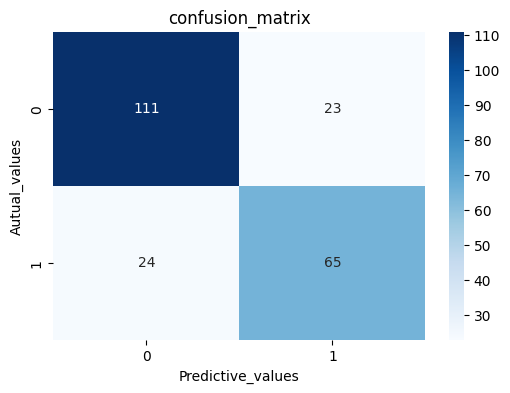

In [56]:

d = confusion_matrix(y_test,y)
plt.figure(figsize=(6,4))
sns.heatmap(d, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predictive_values')
plt.ylabel('Autual_values')
plt.title('confusion_matrix')
plt.show()




In [57]:
from sklearn.ensemble import GradientBoostingClassifier
q=GradientBoostingClassifier(learning_rate=0.05,max_depth=10,max_features=100,random_state=42)
q.fit(x_test,y_test)
t=q.predict(x_test)

In [59]:
print(accuracy_score(y_test,t))
print(confusion_matrix(y_test,t))

0.9506726457399103
[[132   2]
 [  9  80]]


<function matplotlib.pyplot.show(close=None, block=None)>

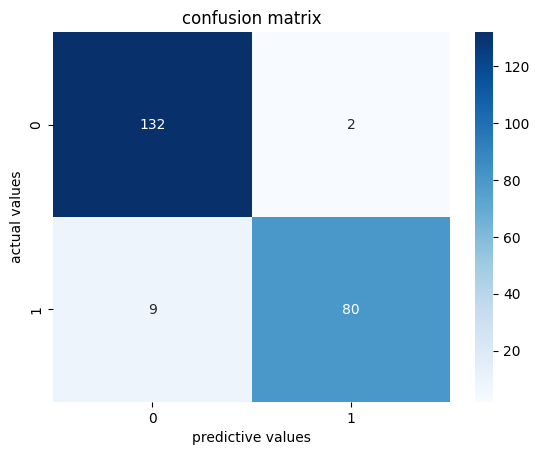

In [61]:
f=confusion_matrix(y_test,t)
plt.Figure((6,4))
sns.heatmap(f,annot=True,fmt='d',cmap='Blues')
plt.xlabel('predictive values')
plt.ylabel('actual values')
plt.title('confusion matrix')
plt.show

In [62]:
from sklearn.neighbors import KNeighborsClassifier
b=KNeighborsClassifier()
b.fit(x_train,y_train)
p=b.predict(x_test)

In [65]:
print(accuracy_score(y_test,p))
print(confusion_matrix(y_test,p))
print(classification_report(y_test,p))

0.7847533632286996
[[111  23]
 [ 25  64]]
              precision    recall  f1-score   support

           0       0.82      0.83      0.82       134
           1       0.74      0.72      0.73        89

    accuracy                           0.78       223
   macro avg       0.78      0.77      0.77       223
weighted avg       0.78      0.78      0.78       223



Text(50.722222222222214, 0.5, 'actual')

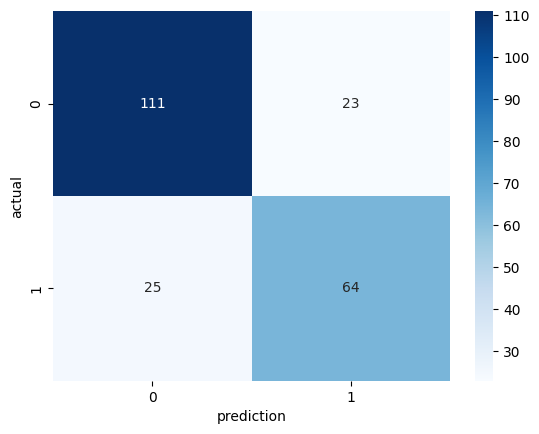

In [80]:
h=confusion_matrix(y_test,p)
plt.Figure(figsize=(6,4))
sns.heatmap(h,annot=True, fmt='d',cmap='Blues')
plt.xlabel('prediction')
plt.ylabel('actual')
